<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bubble Plots**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be directly loaded into pandas for analysis and visualization.

You will use various visualization techniques to explore the data and uncover key trends.


## Objectives


In this lab, you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two data features.

-   Visualize composition of data.

-   Visualize comparison of data.


#### Setup: Working with the Database
**Install and import the needed libraries**


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [2]:
# Step 1: Download the dataset
# !wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Load the data
df = pd.read_csv("survey_data.csv")

# Display the first few rows of the data to understand its structure
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Exploring Data Distributions Using Bubble Plots


#### 1. Bubble Plot for Age vs. Frequency of Participation


- Visualize the relationship between respondents’ age and their participation frequency (`SOPartFreq`) using a bubble plot.

- Use the size of the bubbles to represent their job satisfaction (`JobSat`).


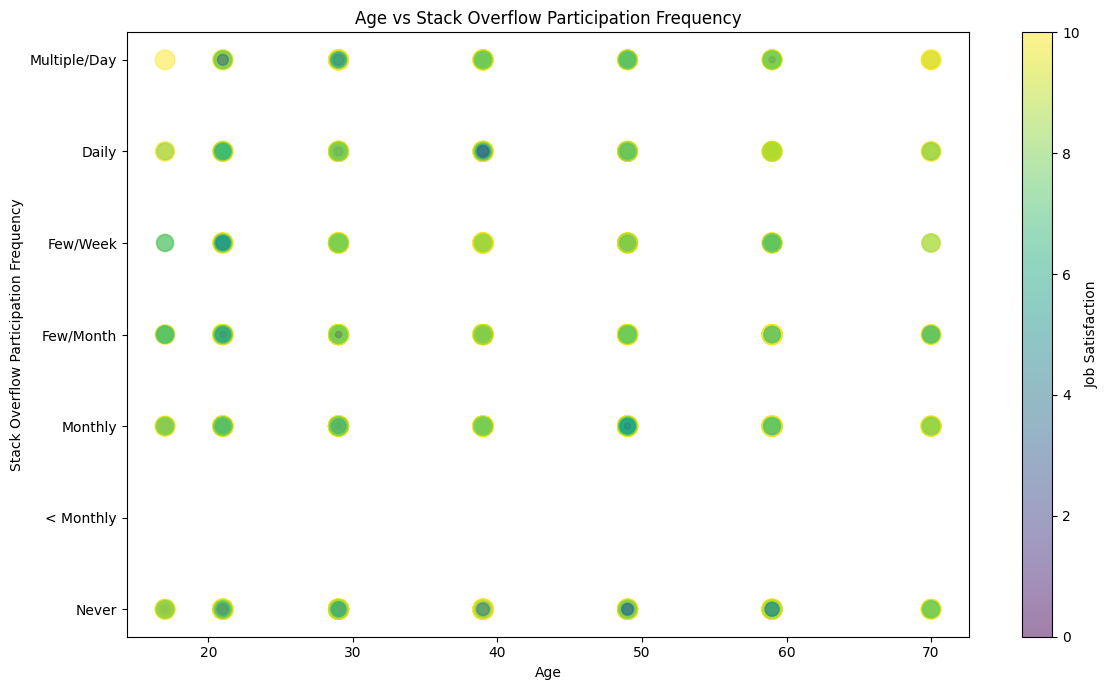

In [8]:
# Map Age to numeric values
age_mapping = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29,
    '35-44 years old': 39,
    '45-54 years old': 49,
    '55-64 years old': 59,
    '65 years or older': 70
}

df['Age_numeric'] = df['Age'].map(age_mapping)

# Map SOPartFreq to an ordinal numeric scale
sopart_mapping = {
    'Multiple times per day': 6,
    'Daily or almost daily': 5,
    'A few times per week': 4,
    'A few times per month or weekly': 3,
    'Less than once per month or monthly': 2,
    'Less than once per month': 1,
    'I have never participated in Q&A on Stack Overflow': 0
}

df['SOPartFreq_numeric'] = df['SOPartFreq'].map(sopart_mapping)

# Ensure JobSat is numeric
df['JobSat'] = pd.to_numeric(df['JobSat'], errors='coerce')

# Keep only the relevant columns and drop NAN values
plot_data = df[['Age_numeric', 'SOPartFreq_numeric', 'JobSat']].dropna()

# Plot a bubble plot
plt.figure(figsize=(12, 7))
plt.scatter(
    plot_data['Age_numeric'],
    plot_data['SOPartFreq_numeric'],
    s=plot_data['JobSat'] * 20,
    c=plot_data['JobSat'],
    cmap='viridis',
    alpha=0.5
)
plt.colorbar(label='Job Satisfaction')
plt.title('Age vs Stack Overflow Participation Frequency')
plt.xlabel('Age')
plt.ylabel('Stack Overflow Participation Frequency')
plt.yticks(
    [0, 1, 2, 3, 4, 5, 6],
    [
        'Never',
        '< Monthly',
        'Monthly',
        'Few/Month',
        'Few/Week',
        'Daily',
        'Multiple/Day'
    ]
)
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Compensation vs. Job Satisfaction


-Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSat`).

- Use the size of the bubbles to represent respondents’ age.


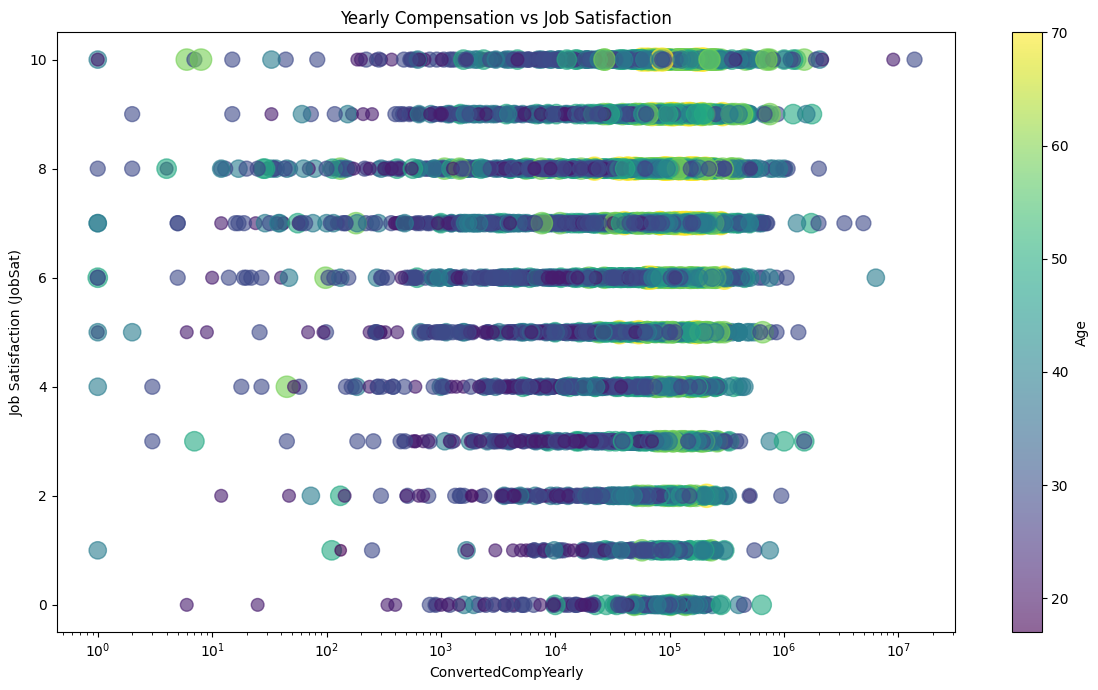

In [10]:
# Ensure columns are numeric
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSat'] = pd.to_numeric(df['JobSat'], errors='coerce')

# Remove missing values
plot_data = df[['ConvertedCompYearly', 'JobSat', 'Age_numeric']].dropna()

# Create bubble plot
plt.figure(figsize=(12, 7))
plt.scatter(
    plot_data['ConvertedCompYearly'],
    plot_data['JobSat'],
    s=plot_data['Age_numeric'] * 4,
    c=plot_data['Age_numeric'],
    alpha=0.6
)
plt.colorbar(label='Age')

plt.title('Yearly Compensation vs Job Satisfaction')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('Job Satisfaction (JobSat)')
plt.xscale('log')
plt.tight_layout()
plt.show()

### Task 2: Analyzing Relationships Using Bubble Plots


#### 1. Bubble Plot of Technology Preferences by Age

- Visualize the popularity of programming languages respondents have worked with (`LanguageHaveWorkedWith`) across age groups.

- Use bubble size to represent the frequency of each language.



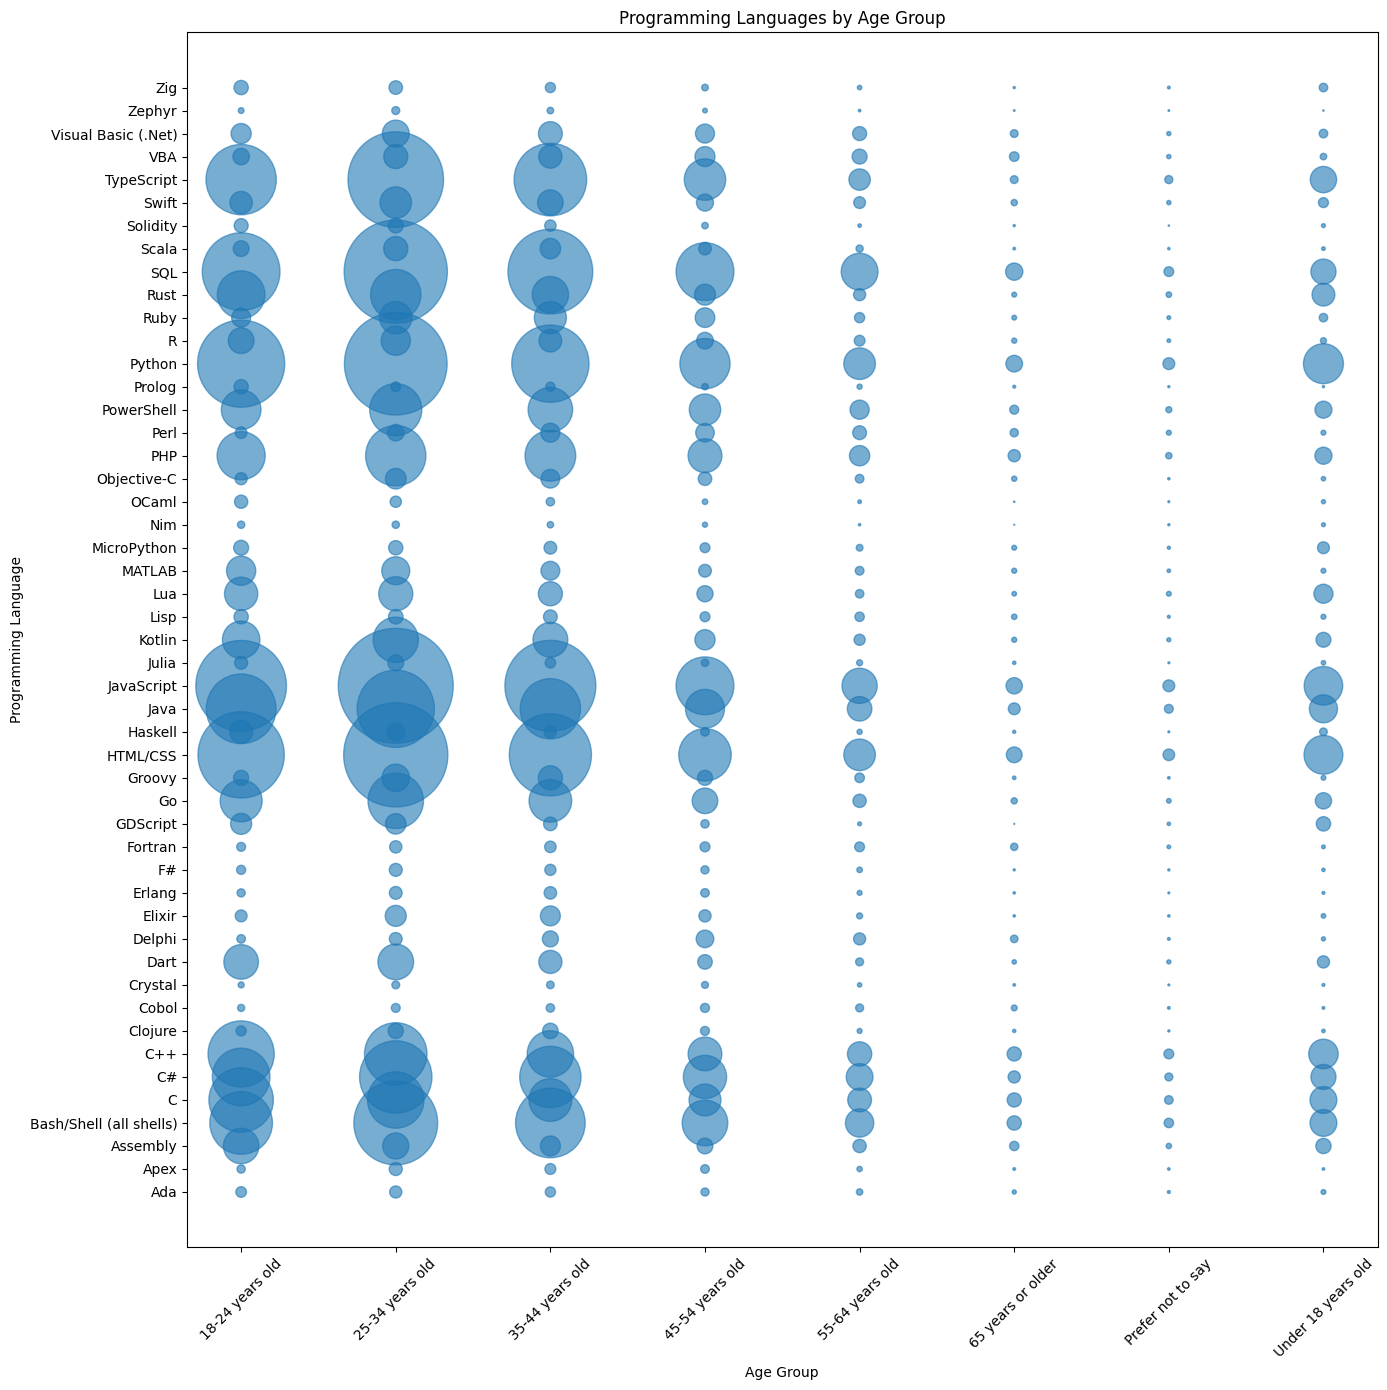

In [14]:
# Keep relevant columns and drop nan values
lang_age = df[['Age', 'LanguageHaveWorkedWith']].dropna()

lang_age['Language'] = lang_age['LanguageHaveWorkedWith'].str.split(';')
lang_age = lang_age.explode('Language')

lang_count = (
    lang_age.groupby(['Age', 'Language']).size().reset_index(name='Frequency')
)

# Bubble plot
plt.figure(figsize=(14,14))
plt.scatter(
    lang_count['Age'],
    lang_count['Language'],
    s=lang_count['Frequency'] * 0.5,
    alpha=0.6
)
plt.title('Programming Languages by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Programming Language')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Preferred Databases vs. Job Satisfaction

- Explore the relationship between preferred databases (`DatabaseWantToWorkWith`) and job satisfaction.

- Use bubble size to indicate the number of respondents for each database.


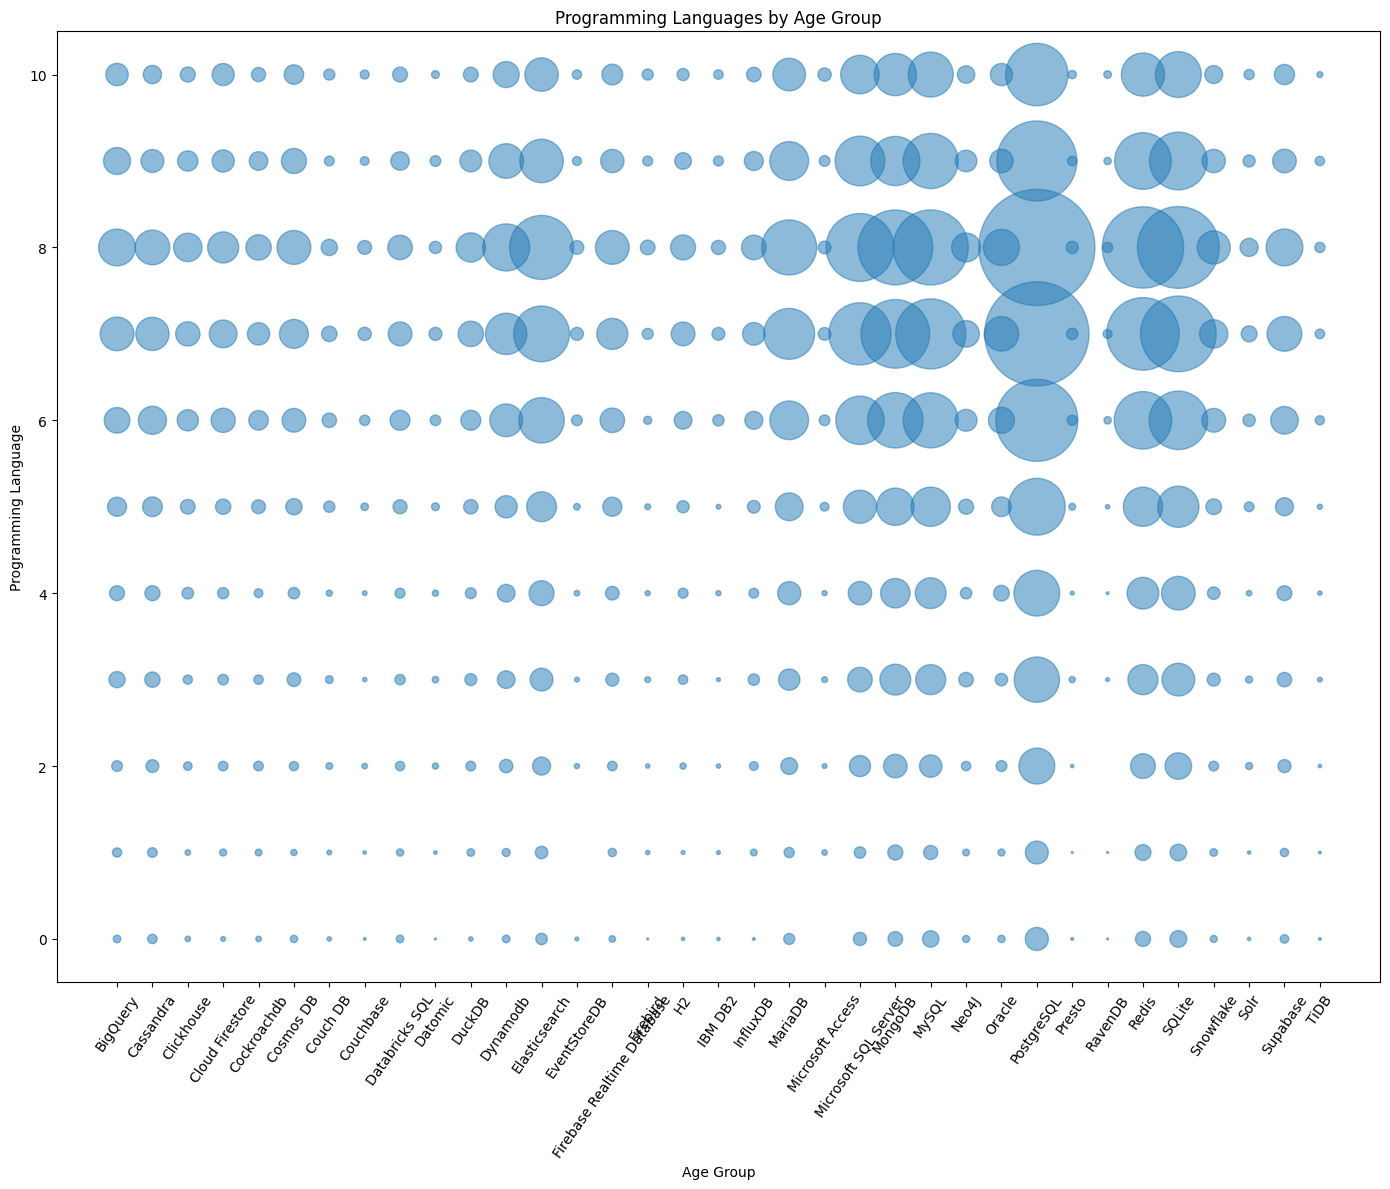

In [18]:
# Keep relevant columns and drop nan values
db_df = df[['DatabaseWantToWorkWith', 'JobSat']].dropna()

# split databases into lists
db_df['Database'] = db_df['DatabaseWantToWorkWith'].str.split(';')
db_df = db_df.explode('Database')

# Clean whitespaces
db_df['Database'] = db_df['Database'].str.strip()

# Get responndent count per database
db_count = (
    db_df.groupby(['Database', 'JobSat']).size()
    .reset_index(name='RespondentCount')
)

plt.figure(figsize=(14,12))
plt.scatter(
    db_count['Database'],
    db_count['JobSat'],
    s=db_count['RespondentCount'] * 2,
    alpha=0.5
)

plt.title('Programming Languages by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Programming Language')
plt.xticks(rotation=55)
plt.tight_layout()
plt.show()

### Task 3: Comparing Data Using Bubble Plots


#### 1. Bubble Plot for Compensation Across Developer Roles

- Visualize compensation (`ConvertedCompYearly`) across different developer roles (`DevType`).

- Use bubble size to represent job satisfaction.


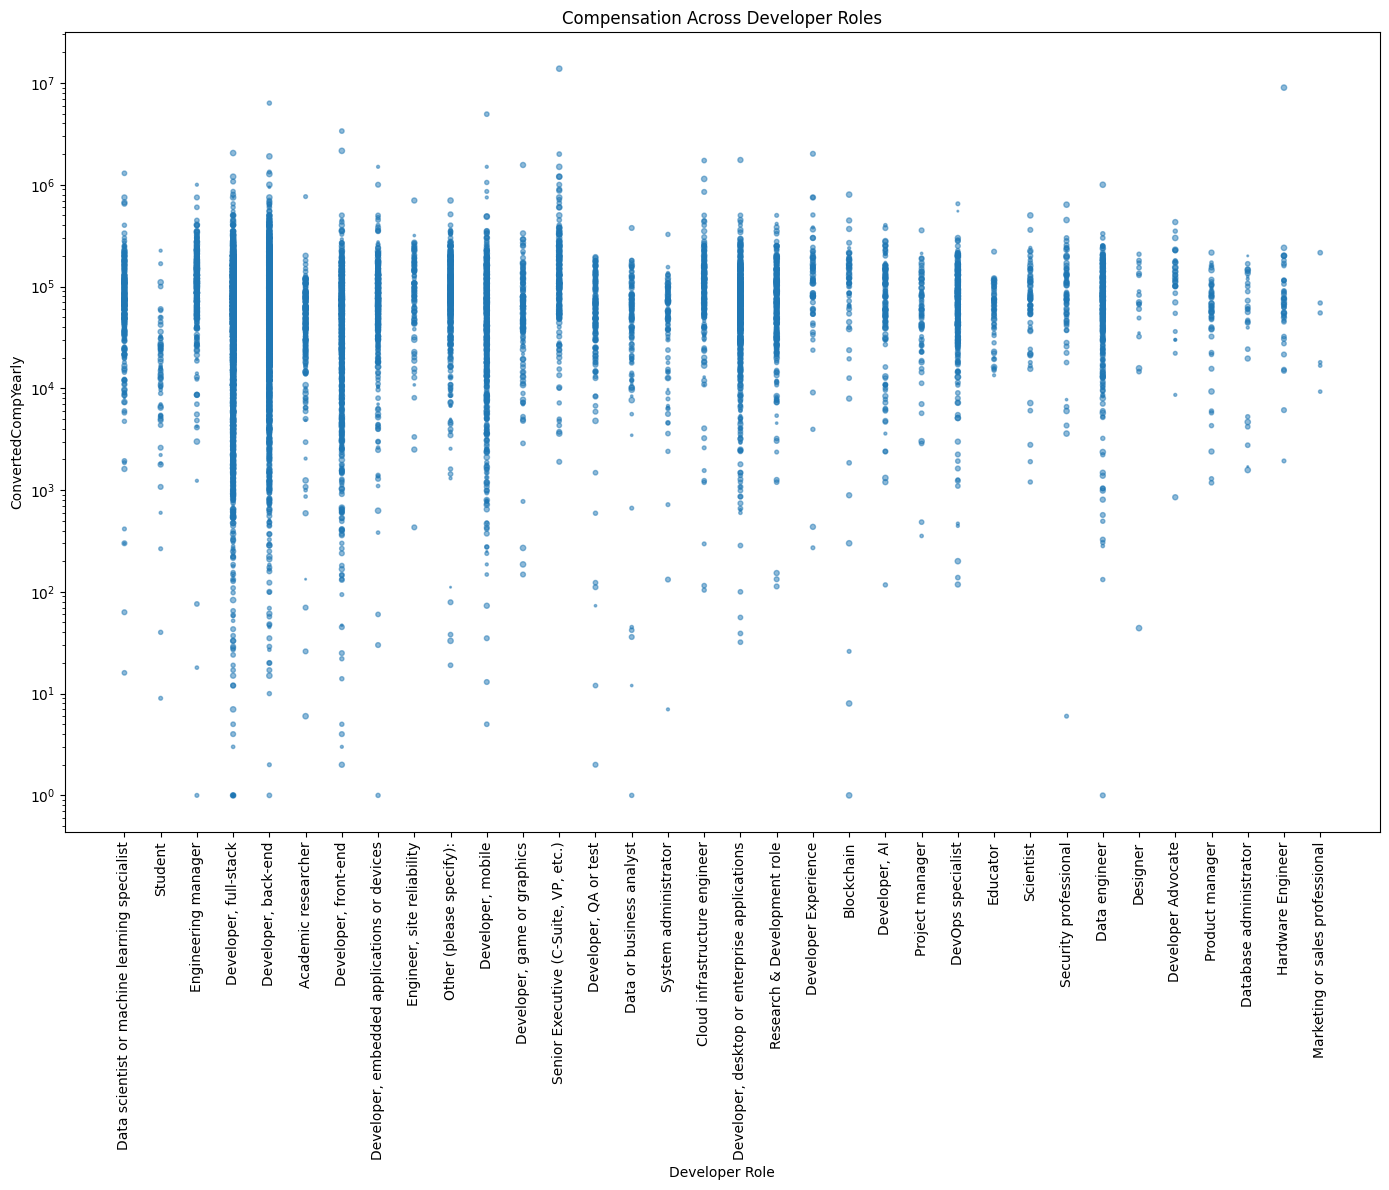

In [22]:
# Keep relevant columns and drop nan values
dev_df = df[['DevType', 'ConvertedCompYearly', 'JobSat']].dropna()

# Split multiple developer roles
dev_df['DevType'] = dev_df['DevType'].str.split(';')
dev_df = dev_df.explode('DevType')

dev_df['DevType'] = dev_df['DevType'].str.strip()

plt.figure(figsize=(14,12))
plt.scatter(
    dev_df['DevType'],
    dev_df['ConvertedCompYearly'],
    s=dev_df['JobSat'] * 1.5,
    alpha=0.5
)
plt.yscale('log')
plt.title('Compensation Across Developer Roles')
plt.xlabel('Developer Role')
plt.ylabel('ConvertedCompYearly')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


#### 2. Bubble Plot for Collaboration Tools by Age

- Visualize the relationship between the collaboration tools used (`NEWCollabToolsHaveWorkedWith`) and age groups.

- Use bubble size to represent the frequency of tool usage.


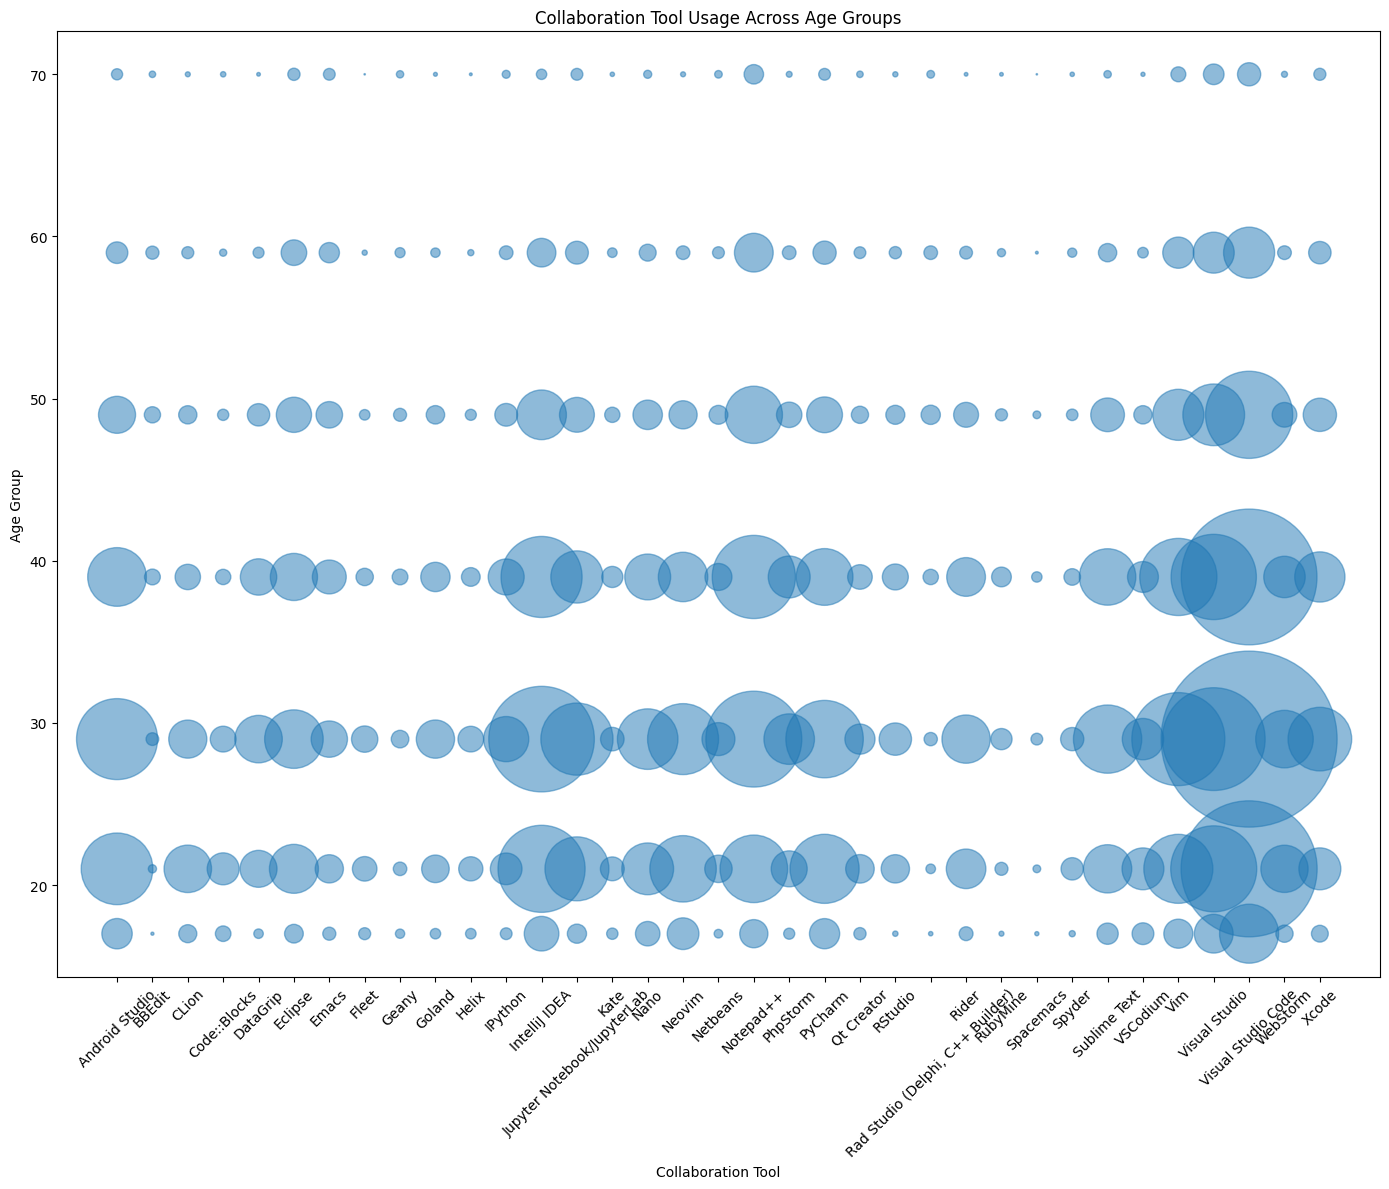

In [26]:
age_mapping = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29,
    '35-44 years old': 39,
    '45-54 years old': 49,
    '55-64 years old': 59,
    '65 years or older': 70
}

df['Age_numeric'] = df['Age'].map(age_mapping)

df_tools = df[['Age_numeric', 'NEWCollabToolsHaveWorkedWith']].dropna()

df_tools['CollabTools'] = df_tools['NEWCollabToolsHaveWorkedWith'].str.split(';')
df_tools = df_tools.explode('CollabTools')
df_tools['CollabTools'] = df_tools['CollabTools'].str.strip()

tool_frequency = (
    df_tools.groupby(['Age_numeric', 'CollabTools']).size()
    .reset_index(name='Frequency')
)
plt.figure(figsize=(14,12))
plt.scatter(
    tool_frequency['CollabTools'],
    tool_frequency['Age_numeric'],
    s=tool_frequency['Frequency'] * 1,
    alpha=0.5
)
plt.title('Collaboration Tool Usage Across Age Groups')
plt.xlabel('Collaboration Tool')
plt.ylabel('Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 4: Visualizing Technology Trends Using Bubble Plots


#### 1. Bubble Plot for Preferred Web Frameworks vs. Job Satisfaction

- Explore the relationship between preferred web frameworks (`WebframeWantToWorkWith`) and job satisfaction.

- Use bubble size to represent the number of respondents.



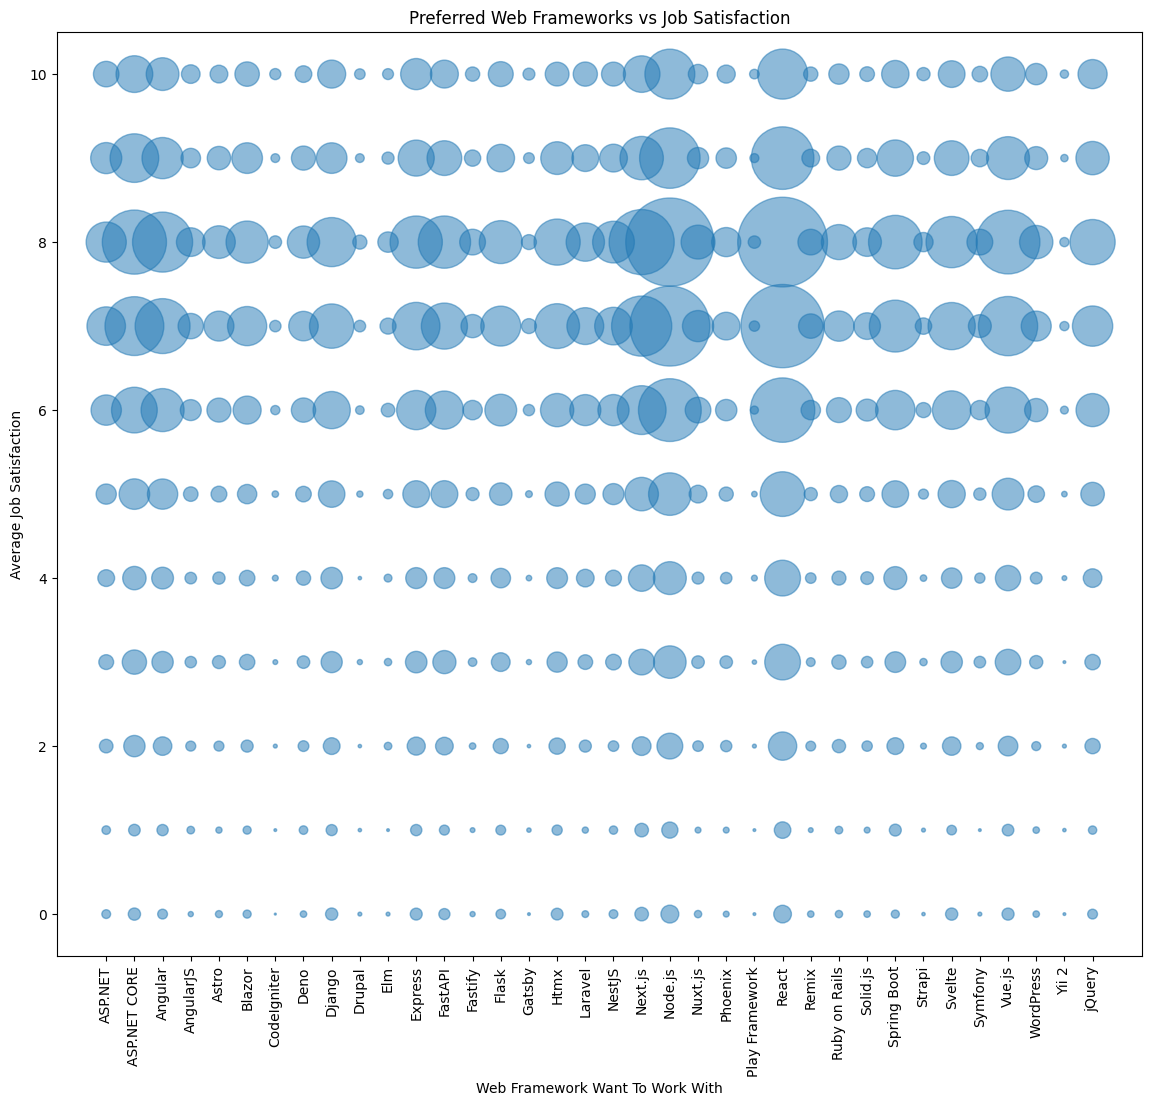

In [28]:
# Keep relevant columns
df_framework = df[['WebframeWantToWorkWith', 'JobSat']].dropna()

# Split frameworks into lists, create rows and remove whitespaces
df_framework['Frameworks'] = df_framework['WebframeWantToWorkWith'].str.split(';')
df_framework = df_framework.explode('Frameworks')
df_framework['Frameworks'] = df_framework['Frameworks'].str.strip()

# Calculate number of respondents
no_of_respondents = (
    df_framework.groupby(['Frameworks', 'JobSat']).size()
    .reset_index(name='Respondents')
)
plt.figure(figsize=(14,12))
plt.scatter(
    no_of_respondents['Frameworks'],
    no_of_respondents['JobSat'],
    s=no_of_respondents['Respondents'] * 2,
    alpha=0.5
)
plt.title('Preferred Web Frameworks vs Job Satisfaction')
plt.xlabel('Web Framework Want To Work With')
plt.ylabel('Average Job Satisfaction')
plt.xticks(rotation=90)
plt.show()



#### 2. Bubble Plot for Admired Technologies Across Countries

- Visualize the distribution of admired technologies (`LanguageAdmired`) across different countries (`Country`).

- Use bubble size to represent the frequency of admiration.



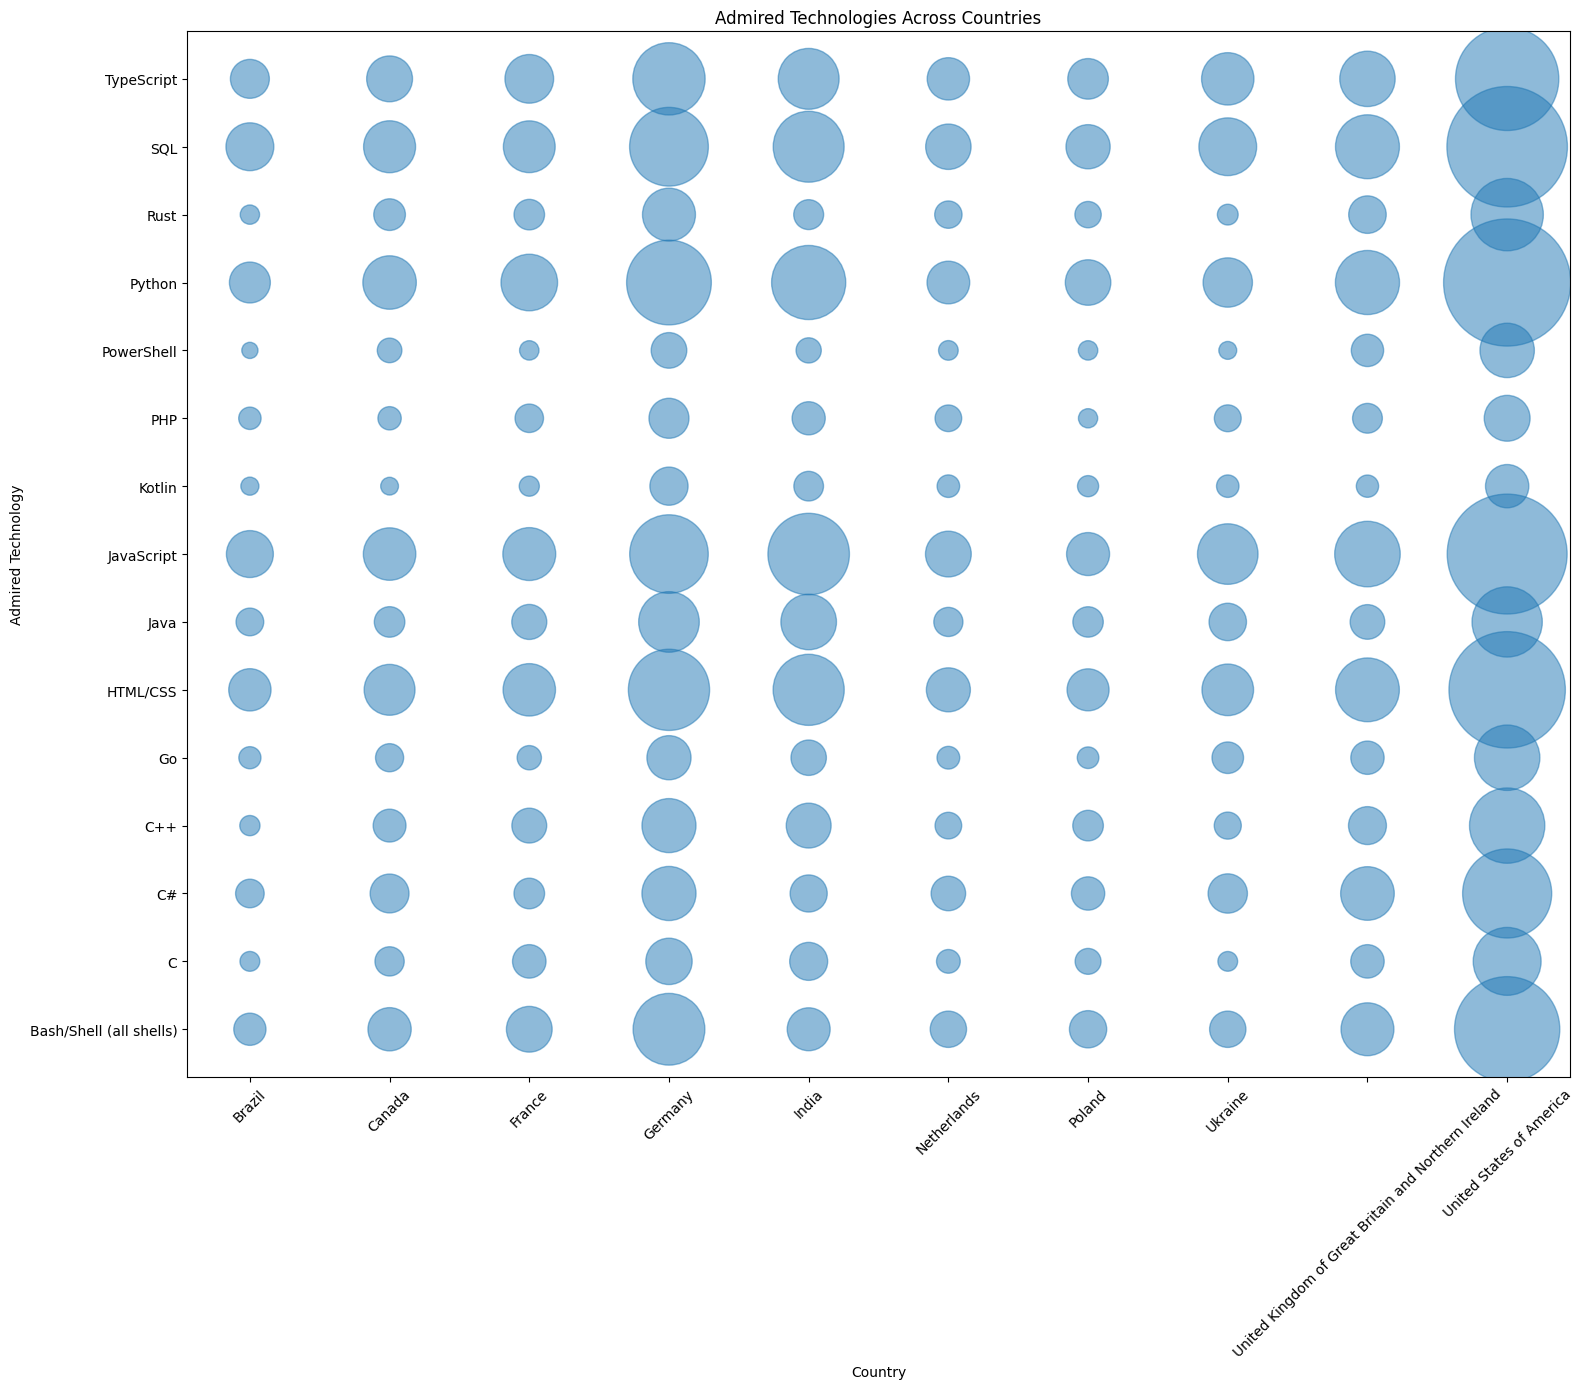

In [34]:
# Keep relevant columns
admired_df = df[['Country', 'LanguageAdmired']].dropna()

# Split admired technologies
admired_df['Language'] = admired_df['LanguageAdmired'].str.split(';')

# Create one row per technology
admired_df = admired_df.explode('Language')

# Remove extra spaces
admired_df['Language'] = admired_df['Language'].str.strip()

# Count admiration frequency by country and technology
admired_counts = (
    admired_df.groupby(['Country', 'Language'])
    .size()
    .reset_index(name='Frequency')
)

# Keep top 10 countries by respondent count
top_countries = (
    admired_df['Country']
    .value_counts()
    .head(10)
    .index
)

# Keep top 15 admired technologies
top_languages = (
    admired_counts.groupby('Language')['Frequency']
    .sum()
    .nlargest(15)
    .index
)

plot_data = admired_counts[
    (admired_counts['Country'].isin(top_countries)) &
    (admired_counts['Language'].isin(top_languages))
]

# Bubble plot
plt.figure(figsize=(16,14))

plt.scatter(
    plot_data['Country'],
    plot_data['Language'],
    s=plot_data['Frequency'] * 2,
    alpha=0.5
)

plt.title('Admired Technologies Across Countries')
plt.xlabel('Country')
plt.ylabel('Admired Technology')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


## Final Step: Review


After completing the lab, you will have extensively used bubble plots to gain insights into developer community preferences, demographics, compensation trends, and job satisfaction.


## Summary


After completing this lab, you will be able to:

- Create and interpret bubble plots to analyze relationships and compositions within datasets.

- Use bubble plots to explore developer preferences, compensation trends, and satisfaction levels.

- Apply bubble plots to visualize complex relationships involving multiple dimensions effectively.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-29|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
